# Tmax vs UTCI Heatwave Comparison — Sulawesi 1996–2025
## V3 — corrected Tmax cache coordinates + paper-style spatial comparison

Versi ini memperbaiki bug penting pada V2: **cache daily Tmax disimpan pada latitude/longitude yang sudah diurutkan ascending**, sedangkan V2 membaca koordinat mentah dari file NetCDF tanpa menerapkan urutan yang sama. Akibatnya indeks koordinat diterapkan ke posisi grid yang salah dan peta Tmax terlihat seperti pita/serpihan.

Perbaikan V3:
- koordinat Tmax dinormalisasi **persis seperti notebook Tmax combined** (`lon` ke −180…180, lalu `lat/lon` diurutkan ascending);
- dilakukan QC bahwa koordinat cache dan target UTCI benar-benar cocok;
- semua analisis case-study dan spatial comparison memakai alignment yang sudah benar;
- peta HWF memakai `contourf` dengan level diskret agar tampil lebih mirip figure jurnal, tanpa membuat data resolusi palsu;
- panel Tmax dan UTCI memakai shared color scale; panel selisih memakai diverging scale simetris.


> **SMOOTH display (adaptasi UTCI Jawa):** peta HWF perbandingan dipetakan dengan interpolasi linear dan mask poligon Sulawesi untuk visualisasi saja. Perhitungan metrics, alignment, dan selisih tetap pada grid asli. Set `SPATIAL_RENDER="native"` untuk pemeriksaan.


## 0. Paket

```bash
pip install numpy pandas xarray netCDF4 matplotlib scipy openpyxl
```


In [1]:
# ============================================================
# 1. IMPORT + KONFIGURASI
# ============================================================

from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.dates as mdates
from matplotlib.colors import TwoSlopeNorm
from netCDF4 import Dataset
from scipy.stats import theilslopes, kendalltau

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ------------------------------------------------------------
# PATH OUTPUT DARI NOTEBOOK TMAX
# ------------------------------------------------------------
TMAX_ROOT = Path(r"D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT")
TMAX_CACHE = TMAX_ROOT / "cache"
TMAX_RESULT = TMAX_ROOT / "results"
TMAX_RAW_DIR = Path(r"D:\MERLI\data\T2M Max")

TMAX_ANNUAL_CSV = TMAX_RESULT / "Annual_Heatwave_Metrics_All_Scenarios.csv"
TMAX_DAILY_DAT = TMAX_CACHE / "daily_tmax_1996_2025.dat"
TMAX_DAILY_DATES = TMAX_CACHE / "daily_dates_1996_2025.npy"
TMAX_META = TMAX_CACHE / "daily_metadata_1996_2025.json"
TMAX_THRESHOLD_NPZ = TMAX_CACHE / "calendar_thresholds_P90_P95_W15_1996_2025.npz"

# ------------------------------------------------------------
# PATH OUTPUT DARI NOTEBOOK UTCI
# ------------------------------------------------------------
UTCI_ROOT = Path(r"D:\MERLI\data\UTCI_Hasil")
UTCI_COMBINED = UTCI_ROOT / "UTCI_Heatwave_Journal_Combined_Output"
UTCI_DATA_DIR = UTCI_COMBINED / "data"

UTCI_DAILY_FILE = UTCI_ROOT / "03_utci_dailymax_1996_2025_C_sulawesi.nc"
UTCI_ANNUAL_CSV = UTCI_DATA_DIR / "Annual_UTCI_Heatwave_Metrics_All_Scenarios.csv"
UTCI_THRESHOLD_FILE = UTCI_DATA_DIR / "UTCI_Thresholds_P90_P95_Calendar15day_1996_2025.nc"
UTCI_METRICS_FILE = UTCI_DATA_DIR / "UTCI_Heatwave_Metrics_AllScenarios_1996_2025.nc"

# ------------------------------------------------------------
# OUTPUT NOTEBOOK PERBANDINGAN
# ------------------------------------------------------------
OUTPUT_DIR = Path(r"D:\MERLI\data\TMAX_UTCI_COMPARISON")
PLOT_DIR = OUTPUT_DIR / "plots_v2_pretty"
TABLE_DIR = OUTPUT_DIR / "tables_v2_pretty"
for folder in [OUTPUT_DIR, PLOT_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# ANALISIS
# ------------------------------------------------------------
START_YEAR = 1996
END_YEAR = 2025
MAIN_SCENARIO = "P90_D3"
INTENSITY_MODE = "absolute"   # "absolute" atau "excess"

# Case study
AUTO_CASE = True
CASE_SELECTION = "overlap"    # overlap | contrast | tmax | utci
CASE_CENTER = "2016-04-15"    # dipakai hanya jika AUTO_CASE = False
CASE_HALF_WINDOW_DAYS = 10     # total window = 21 hari
CORE_ACTIVITY_FRACTION = 0.30

# ------------------------------------------------------------
# PENYELARASAN GRID
# ------------------------------------------------------------
GRID_TOL = 1e-4
ALLOW_INTERPOLATION = False

# Tampilan peta
MAP_EXTENT = [118.0, 127.0, -7.0, 2.5]  # sulawesi penuh
SPATIAL_RENDER = "smooth"  # "native" untuk QC
DISPLAY_NX = 460
DISPLAY_NY = 490
FIG_DPI = 400
SAVE_PDF = True

# ------------------------------------------------------------
# STYLE JURNAL
# ------------------------------------------------------------
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 9.5,
    "axes.titlesize": 10.5,
    "axes.labelsize": 9.5,
    "xtick.labelsize": 8.3,
    "ytick.labelsize": 8.3,
    "legend.fontsize": 8.2,
    "figure.titlesize": 13.5,
    "axes.linewidth": 0.8,
    "savefig.facecolor": "white",
    "figure.facecolor": "white",
})

required = [
    TMAX_ANNUAL_CSV, TMAX_DAILY_DAT, TMAX_DAILY_DATES, TMAX_META,
    TMAX_THRESHOLD_NPZ, UTCI_DAILY_FILE, UTCI_ANNUAL_CSV,
    UTCI_THRESHOLD_FILE, UTCI_METRICS_FILE,
]
missing = [p for p in required if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Ada output workflow sebelumnya yang belum ditemukan:\n" +
        "\n".join(str(p) for p in missing) +
        "\n\nJalankan dulu notebook TMAX combined dan UTCI combined sampai selesai."
    )

print("Main scenario  :", MAIN_SCENARIO)
print("Intensity      :", INTENSITY_MODE)
print("Case selection :", CASE_SELECTION)
print("Output         :", OUTPUT_DIR)


Main scenario  : P90_D3
Intensity      : absolute
Case selection : overlap
Output         : D:\MERLI\data\TMAX_UTCI_COMPARISON


## 2. Load annual metrics dan buat Figure 1

Figure ini menjawab pertanyaan paling gampang:

> **Apakah pola tahunan HWN, HWF, HWD, HWA, dan HWM dari definisi Tmax mirip atau berbeda dengan definisi UTCI?**

Untuk HWA/HWM, default menggunakan nilai absolut. Ingat: UTCI adalah indeks temperatur ekuivalen, jadi perbandingan magnitudo harus dibaca sebagai **perbandingan indeks**, bukan dianggap dua pengukuran suhu udara yang identik.


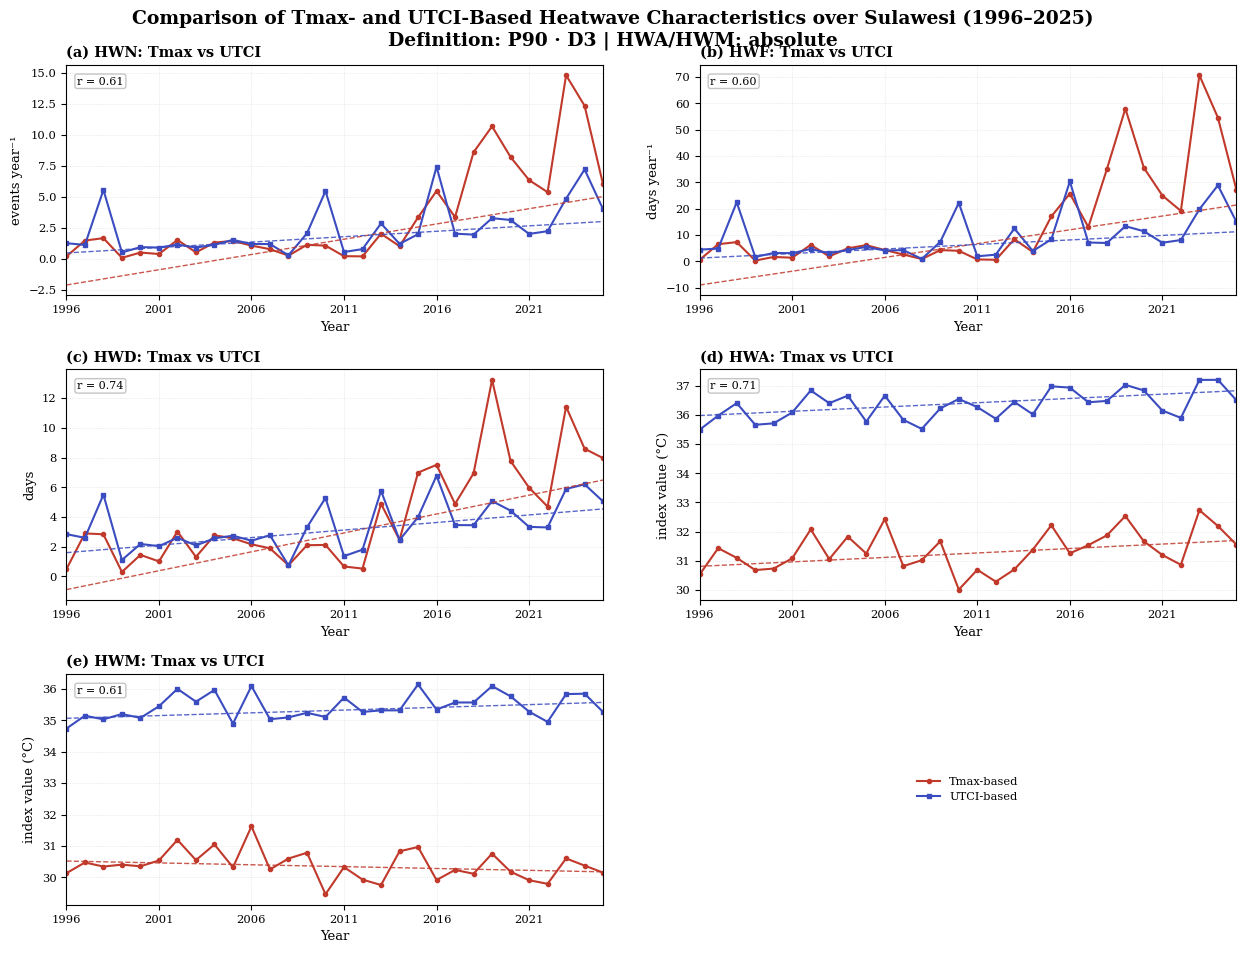

,metric,basis,sen_slope_per_decade,kendall_p
0,HWN,Tmax,2.468348,0.000029
1,HWN,UTCI,0.876729,0.000654
2,HWF,Tmax,10.474116,0.000060
3,HWF,UTCI,3.446248,0.003269
4,HWD,Tmax,2.543320,0.000084
5,HWD,UTCI,1.014867,0.002543
6,HWA,Tmax,0.304929,0.041219
7,HWA,UTCI,0.292965,0.001966
8,HWM,Tmax,-0.118200,0.176636
9,HWM,UTCI,0.174490,0.023648


In [2]:
# ============================================================
# 2. ANNUAL CHARACTERISTICS COMPARISON
# ============================================================

tmax_df = pd.read_csv(TMAX_ANNUAL_CSV)
utci_df = pd.read_csv(UTCI_ANNUAL_CSV)

for name, df in [("Tmax", tmax_df), ("UTCI", utci_df)]:
    if MAIN_SCENARIO not in set(df["scenario"].astype(str)):
        raise ValueError(f"{MAIN_SCENARIO} tidak tersedia pada CSV {name}.")

if INTENSITY_MODE == "absolute":
    hwa_col, hwm_col = "HWA_abs", "HWM_abs"
    intensity_label = "index value (°C)"
else:
    hwa_col, hwm_col = "HWA_excess", "HWM_excess"
    intensity_label = "exceedance above threshold (°C)"

T = tmax_df[tmax_df["scenario"] == MAIN_SCENARIO].sort_values("year").copy()
U = utci_df[utci_df["scenario"] == MAIN_SCENARIO].sort_values("year").copy()

if not np.array_equal(T["year"].to_numpy(), U["year"].to_numpy()):
    raise ValueError("Tahun Tmax dan UTCI tidak identik.")

years = T["year"].to_numpy(dtype=int)

specs = [
    ("HWN", "HWN", "events year⁻¹"),
    ("HWF", "HWF", "days year⁻¹"),
    ("HWD", "HWD", "days"),
    (hwa_col, "HWA", intensity_label),
    (hwm_col, "HWM", intensity_label),
]

fig = plt.figure(figsize=(13.0, 10.0))
gs = fig.add_gridspec(3, 2, hspace=0.32, wspace=0.18, left=0.08, right=0.98, bottom=0.07, top=0.91)

axes = []
summary_rows = []
for i, (col, short, ylabel) in enumerate(specs):
    ax = fig.add_subplot(gs[i // 2, i % 2])
    axes.append(ax)

    y_t = T[col].to_numpy(dtype=float)
    y_u = U[col].to_numpy(dtype=float)

    ax.plot(years, y_t, color="#c0392b", marker="o", markersize=3.0, linewidth=1.5, label="Tmax-based")
    ax.plot(years, y_u, color="#3b4cc0", marker="s", markersize=2.8, linewidth=1.5, label="UTCI-based")

    # Theil–Sen trend untuk keduanya
    for y, color, name in [(y_t, "#c0392b", "Tmax"), (y_u, "#3b4cc0", "UTCI")]:
        m = np.isfinite(y)
        if m.sum() >= 10:
            ts = theilslopes(y[m], years[m], alpha=0.95)
            trend = ts.intercept + ts.slope * years
            ax.plot(years, trend, color=color, linestyle="--", linewidth=1.0, alpha=0.85)
            tau = kendalltau(years[m], y[m])
            summary_rows.append({
                "metric": short,
                "basis": name,
                "sen_slope_per_decade": ts.slope * 10.0,
                "kendall_p": tau.pvalue,
            })

    # korelasi antar dua definisi
    common = np.isfinite(y_t) & np.isfinite(y_u)
    r = np.corrcoef(y_t[common], y_u[common])[0, 1] if common.sum() >= 3 else np.nan
    ax.text(
        0.02, 0.95, f"r = {r:.2f}" if np.isfinite(r) else "r = NA",
        transform=ax.transAxes, va="top", ha="left", fontsize=8,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="0.75", alpha=0.9),
    )

    ax.set_title(f"({chr(97+i)}) {short}: Tmax vs UTCI", fontweight="bold", loc="left")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Year")
    ax.set_xlim(START_YEAR, END_YEAR)
    ax.set_xticks(np.arange(START_YEAR, END_YEAR + 1, 5))
    ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.45)

ax_leg = fig.add_subplot(gs[2, 1])
ax_leg.axis("off")
handles, labels = axes[0].get_legend_handles_labels()
ax_leg.legend(handles[:2], labels[:2], loc="center", frameon=False)

fig.suptitle(
    f"Comparison of Tmax- and UTCI-Based Heatwave Characteristics over Sulawesi ({START_YEAR}–{END_YEAR})\n"
    f"Definition: {MAIN_SCENARIO.replace('_', ' · ')} | HWA/HWM: {INTENSITY_MODE}",
    fontweight="bold", y=0.965,
)

out_png = PLOT_DIR / f"FIG01_Annual_TMAX_vs_UTCI_{MAIN_SCENARIO}_{INTENSITY_MODE}.png"
fig.savefig(out_png, dpi=FIG_DPI, bbox_inches="tight")
if SAVE_PDF:
    fig.savefig(out_png.with_suffix(".pdf"), bbox_inches="tight")
plt.show()
plt.close(fig)

annual_trend_summary = pd.DataFrame(summary_rows)
annual_trend_summary.to_csv(TABLE_DIR / "Annual_Comparison_Trend_Summary.csv", index=False)
annual_trend_summary


## 3. Load data harian Tmax + UTCI dan selaraskan grid

Versi V2 **tidak lagi memaksa kedua indeks memakai irisan mask untuk semua analisis**. Itu yang membuat versi sebelumnya terlihat kurus/sparse.

- Tmax dan UTCI tetap disejajarkan koordinatnya untuk analisis agreement.
- **Affected area** masing-masing indeks dihitung pada valid area-nya sendiri.
- Common grid hanya dipakai saat benar-benar diperlukan: `both`, `Tmax only`, `UTCI only`, dan difference map.


In [3]:
# ============================================================
# 3A. LOAD TMAX DAILY CACHE + COORDINATES — FIXED GRID ORDER
# ============================================================

meta = json.loads(TMAX_META.read_text(encoding="utf-8"))
tmax_shape = tuple(meta["shape"])
tmax_dates = np.load(TMAX_DAILY_DATES).astype("datetime64[D]")
tmax_values = np.memmap(
    TMAX_DAILY_DAT,
    dtype=np.float32,
    mode="r",
    shape=tmax_shape,
)

# ------------------------------------------------------------
# PENTING:
# Notebook Tmax combined melakukan:
# 1) longitude 0..360 -> -180..180 bila perlu
# 2) sort longitude ascending
# 3) sort latitude ascending
# 4) baru menyimpan data ke daily cache
#
# Karena itu koordinat yang dibaca dari file mentah HARUS
# dinormalisasi dengan cara yang sama sebelum dipakai untuk
# mengindeks daily cache. V2 tidak melakukan ini.
# ------------------------------------------------------------
raw_files = sorted(TMAX_RAW_DIR.glob("*.nc"))
if not raw_files:
    raise FileNotFoundError(f"Tidak ada file .nc di {TMAX_RAW_DIR}")

with Dataset(raw_files[0], "r") as nc:
    lat_name = next(
        (n for n in ["latitude", "lat", "Latitude", "LAT"] if n in nc.variables),
        None,
    )
    lon_name = next(
        (n for n in ["longitude", "lon", "Longitude", "LON"] if n in nc.variables),
        None,
    )
    if lat_name is None or lon_name is None:
        raise KeyError("Koordinat latitude/longitude tidak ditemukan di file Tmax contoh.")

    raw_lat = np.asarray(nc.variables[lat_name][:], dtype=float)
    raw_lon = np.asarray(nc.variables[lon_name][:], dtype=float)

# Longitude sama seperti read_tmax_file() pada notebook Tmax combined
if np.nanmax(raw_lon) > 180:
    raw_lon = ((raw_lon + 180) % 360) - 180

# Cache disimpan setelah sorting ascending
lat_order = np.argsort(raw_lat)
lon_order = np.argsort(raw_lon)
tmax_lat = raw_lat[lat_order]
tmax_lon = raw_lon[lon_order]

if (len(tmax_lat), len(tmax_lon)) != tmax_shape[1:]:
    raise ValueError(
        "Ukuran koordinat Tmax yang dinormalisasi tidak cocok dengan shape cache daily Tmax."
    )

if np.any(np.diff(tmax_lat) <= 0):
    raise ValueError("Latitude Tmax cache seharusnya strictly ascending.")
if np.any(np.diff(tmax_lon) <= 0):
    raise ValueError("Longitude Tmax cache seharusnya strictly ascending.")

print("Tmax daily cache :", tmax_values.shape)
print("Tmax grid cache  :", len(tmax_lat), "x", len(tmax_lon))
print("Lat cache range  :", float(tmax_lat.min()), "s.d.", float(tmax_lat.max()))
print("Lon cache range  :", float(tmax_lon.min()), "s.d.", float(tmax_lon.max()))
print("Latitude order   : ascending [FIXED]")
print("Longitude order  : ascending [FIXED]")


Tmax daily cache : (10958, 57, 45)
Tmax grid cache  : 57 x 45
Lat cache range  : -7.0 s.d. 7.0
Lon cache range  : 116.0 s.d. 127.0
Latitude order   : ascending [FIXED]
Longitude order  : ascending [FIXED]


In [4]:
# ============================================================
# 3B. LOAD UTCI DAILY + ALIGN TMAX TO UTCI GRID
# ============================================================

utci_ds = xr.open_dataset(
    UTCI_DAILY_FILE,
    engine="netcdf4",
    decode_times=True,
    decode_timedelta=False,
)
utci_da = utci_ds["utci_max"].transpose("time", "latitude", "longitude")
utci_values = np.asarray(utci_da.values, dtype=np.float32)
utci_dates = pd.DatetimeIndex(utci_da["time"].values).to_numpy(dtype="datetime64[D]")
utci_lat = np.asarray(utci_ds["latitude"].values, dtype=float)
utci_lon = np.asarray(utci_ds["longitude"].values, dtype=float)

if not np.array_equal(tmax_dates, utci_dates):
    raise ValueError("Tanggal daily Tmax dan UTCI tidak identik.")


def find_coord_indices(source_coord, target_coord, tol=1e-4, label="coord"):
    source_coord = np.asarray(source_coord, dtype=float)
    target_coord = np.asarray(target_coord, dtype=float)
    idx = []
    misses = []
    for value in target_coord:
        hits = np.where(np.isclose(source_coord, value, atol=tol, rtol=0))[0]
        if len(hits) == 1:
            idx.append(int(hits[0]))
        else:
            misses.append((float(value), len(hits)))
    if misses:
        raise ValueError(
            f"Tidak semua {label} UTCI ditemukan unik pada grid Tmax. "
            f"Contoh gagal: {misses[:8]}. Regridding eksplisit diperlukan."
        )
    return np.asarray(idx, dtype=int)


grid_identical = (
    tmax_values.shape[1:] == utci_values.shape[1:]
    and np.allclose(tmax_lat, utci_lat, atol=GRID_TOL, rtol=0)
    and np.allclose(tmax_lon, utci_lon, atol=GRID_TOL, rtol=0)
)

if grid_identical:
    tmax_lat_idx = np.arange(len(tmax_lat), dtype=int)
    tmax_lon_idx = np.arange(len(tmax_lon), dtype=int)
    alignment_mode = "identical"
else:
    try:
        tmax_lat_idx = find_coord_indices(tmax_lat, utci_lat, GRID_TOL, "latitude")
        tmax_lon_idx = find_coord_indices(tmax_lon, utci_lon, GRID_TOL, "longitude")
        alignment_mode = "Tmax subset to UTCI grid (no interpolation)"
    except ValueError as err:
        if not ALLOW_INTERPOLATION:
            print("\nDIAGNOSTIK GRID")
            print("Tmax lat n/range:", len(tmax_lat), float(np.min(tmax_lat)), float(np.max(tmax_lat)))
            print("UTCI lat n/range:", len(utci_lat), float(np.min(utci_lat)), float(np.max(utci_lat)))
            print("Tmax lon n/range:", len(tmax_lon), float(np.min(tmax_lon)), float(np.max(tmax_lon)))
            print("UTCI lon n/range:", len(utci_lon), float(np.min(utci_lon)), float(np.max(utci_lon)))
            raise ValueError(str(err))
        raise NotImplementedError("Interpolation fallback belum diaktifkan.")

# Tmax disubset mengikuti grid UTCI, TANPA interpolasi
tmax_values_cmp = np.take(
    np.take(tmax_values, tmax_lat_idx, axis=1),
    tmax_lon_idx,
    axis=2,
).astype(np.float32, copy=False)

utci_values_cmp = utci_values
cmp_lat = utci_lat.copy()
cmp_lon = utci_lon.copy()

if tmax_values_cmp.shape != utci_values_cmp.shape:
    raise RuntimeError(
        f"Setelah alignment shape masih berbeda: Tmax={tmax_values_cmp.shape}, UTCI={utci_values_cmp.shape}"
    )

aligned_lat = tmax_lat[tmax_lat_idx]
aligned_lon = tmax_lon[tmax_lon_idx]
if not np.allclose(aligned_lat, cmp_lat, atol=GRID_TOL, rtol=0):
    raise RuntimeError("Latitude hasil subset Tmax belum sama dengan UTCI.")
if not np.allclose(aligned_lon, cmp_lon, atol=GRID_TOL, rtol=0):
    raise RuntimeError("Longitude hasil subset Tmax belum sama dengan UTCI.")

# PENTING: valid mask dipertahankan TERPISAH.
tmax_valid_grid = np.any(np.isfinite(tmax_values_cmp), axis=0)
utci_valid_grid = np.any(np.isfinite(utci_values_cmp), axis=0)
common_grid = tmax_valid_grid & utci_valid_grid

print("Tmax daily asli      :", tmax_values.shape)
print("UTCI daily           :", utci_values.shape)
print("Alignment mode       :", alignment_mode)
print("Grid comparison      :", tmax_values_cmp.shape[1:])
print("Tmax valid grid      :", int(tmax_valid_grid.sum()))
print("UTCI valid grid      :", int(utci_valid_grid.sum()))
print("Common valid grid    :", int(common_grid.sum()))
print("Lat comparison range :", float(cmp_lat.min()), "s.d.", float(cmp_lat.max()))
print("Lon comparison range :", float(cmp_lon.min()), "s.d.", float(cmp_lon.max()))


Tmax daily asli      : (10958, 57, 45)
UTCI daily           : (10958, 44, 32)
Alignment mode       : Tmax subset to UTCI grid (no interpolation)
Grid comparison      : (44, 32)
Tmax valid grid      : 242
UTCI valid grid      : 242
Common valid grid    : 242
Lat comparison range : -6.25 s.d. 4.5
Lon comparison range : 119.0 s.d. 126.75


### QC alignment yang wajib dicek

Setelah cell alignment dijalankan, lihat output `Tmax valid grid`, `UTCI valid grid`, dan `Common valid grid`. Karena UTCI STEP 2 memakai mask Sulawesi yang berasal dari workflow Tmax, ketiganya seharusnya **sangat dekat**. Kalau Tmax valid grid masih tinggal sedikit dibanding UTCI, jangan lanjut interpretasi figure—berarti ada file/cache lama yang belum dibangun ulang.


## 4. Bangun threshold harian dan mask event untuk skenario utama

Versi V2 menghitung heatwave Tmax dan UTCI pada **valid mask masing-masing**, bukan langsung pada irisan mask. Ini penting supaya peta dan affected-area tidak kehilangan banyak grid hanya gara-gara mask kedua dataset sedikit berbeda.


In [5]:
# ============================================================
# 4. DAILY THRESHOLDS + EVENT MASKS
# ============================================================

m = re.fullmatch(r"P(\d+)_D(\d+)", MAIN_SCENARIO)
if not m:
    raise ValueError("MAIN_SCENARIO harus format P90_D3, P95_D4, dll.")
P = int(m.group(1))
D = int(m.group(2))

zt = np.load(TMAX_THRESHOLD_NPZ)
tmax_thr_cal_raw = np.asarray(zt[f"P{P}"], dtype=np.float32)

utci_thr_ds = xr.open_dataset(UTCI_THRESHOLD_FILE, engine="netcdf4", decode_timedelta=False)
utci_thr_cal = np.asarray(utci_thr_ds[f"P{P}"].values, dtype=np.float32)

# Tmax threshold ikut disubset ke grid UTCI
tmax_thr_cal = np.take(
    np.take(tmax_thr_cal_raw, tmax_lat_idx, axis=1),
    tmax_lon_idx,
    axis=2,
).astype(np.float32, copy=False)

if tmax_thr_cal.shape != utci_thr_cal.shape:
    raise ValueError(
        f"Setelah alignment shape threshold berbeda: Tmax={tmax_thr_cal.shape}, UTCI={utci_thr_cal.shape}"
    )

all_dates = pd.DatetimeIndex(tmax_dates.astype("datetime64[ns]"))


def noleap_day_index(dti):
    out = np.full(len(dti), -1, dtype=np.int16)
    for i, ts in enumerate(dti):
        if ts.month == 2 and ts.day == 29:
            continue
        doy = ts.dayofyear - 1
        if ts.is_leap_year and ts.month > 2:
            doy -= 1
        out[i] = doy
    return out

idx = noleap_day_index(all_dates)


def calendar_to_daily(cal):
    out = np.full((len(idx), cal.shape[1], cal.shape[2]), np.nan, dtype=np.float32)
    regular = idx >= 0
    out[regular] = cal[idx[regular]]
    feb29 = idx < 0
    if np.any(feb29):
        out[feb29] = 0.5 * (cal[58] + cal[59])
    return out


tmax_thr_daily = calendar_to_daily(tmax_thr_cal)
utci_thr_daily = calendar_to_daily(utci_thr_cal)


def compute_event_mask(exceed, min_duration):
    ntime = exceed.shape[0]
    run_end = np.zeros(exceed.shape, dtype=np.int16)
    run = np.zeros(exceed.shape[1:], dtype=np.int16)
    for t in range(ntime):
        run = np.where(exceed[t], run + 1, 0).astype(np.int16)
        run_end[t] = run

    event_mask = np.zeros(exceed.shape, dtype=bool)
    run = np.zeros(exceed.shape[1:], dtype=np.int16)
    for t in range(ntime - 1, -1, -1):
        run = np.where(exceed[t], run + 1, 0).astype(np.int16)
        event_mask[t] = exceed[t] & ((run_end[t] + run - 1) >= min_duration)
    return event_mask


# Heatwave dihitung pada valid mask masing-masing
tmax_valid_3d = np.isfinite(tmax_values_cmp) & np.isfinite(tmax_thr_daily)
utci_valid_3d = np.isfinite(utci_values_cmp) & np.isfinite(utci_thr_daily)

tmax_exceed = tmax_valid_3d & (tmax_values_cmp > tmax_thr_daily)
utci_exceed = utci_valid_3d & (utci_values_cmp > utci_thr_daily)

tmax_hw = compute_event_mask(tmax_exceed, D)
utci_hw = compute_event_mask(utci_exceed, D)

# Common grid hanya untuk agreement/difference
common_valid_3d = tmax_valid_3d & utci_valid_3d & common_grid[None, :, :]

print("Threshold shape:", tmax_thr_cal.shape)
print("Tmax heatwave grid-days:", int(tmax_hw.sum()))
print("UTCI heatwave grid-days:", int(utci_hw.sum()))
print("Common-support grid-days:", int(common_valid_3d.sum()))


Threshold shape: (365, 44, 32)
Tmax heatwave grid-days: 108486
UTCI heatwave grid-days: 66362
Common-support grid-days: 2651836


## 5. Pilih case study otomatis

Default `CASE_SELECTION = "overlap"` memilih periode ketika **keduanya sama-sama aktif**, supaya figure perbandingan tidak malah menampilkan satu indeks hidup sendirian dan indeks lain tidur.

Pilihan lain:
- `contrast` = perbedaan Tmax–UTCI terbesar;
- `tmax` = kejadian Tmax paling luas;
- `utci` = kejadian UTCI paling luas.


In [6]:
# ============================================================
# 5. AUTO CASE SELECTION — AREA-WEIGHTED FRACTION
# ============================================================

area_weights = np.cos(np.deg2rad(cmp_lat))[:, None] * np.ones((1, len(cmp_lon)))


def weighted_fraction_ts(mask3d, static_grid):
    """Persentase area berbobot cos(latitude) yang True setiap hari."""
    w = area_weights.copy()
    w[~static_grid] = np.nan
    denom = np.nansum(w)
    out = np.zeros(mask3d.shape[0], dtype=float)
    if denom <= 0:
        out[:] = np.nan
        return out
    for t in range(mask3d.shape[0]):
        out[t] = 100.0 * np.nansum(np.where(mask3d[t], w, 0.0)) / denom
    return out


tmax_area_full = weighted_fraction_ts(tmax_hw, tmax_valid_grid)
utci_area_full = weighted_fraction_ts(utci_hw, utci_valid_grid)

both_mask_full = tmax_hw & utci_hw & common_valid_3d
both_area_full = weighted_fraction_ts(both_mask_full, common_grid)

if AUTO_CASE:
    if CASE_SELECTION == "overlap":
        # mengutamakan overlap dan tetap mempertimbangkan aktivitas keduanya
        score = 2.0 * both_area_full + np.minimum(tmax_area_full, utci_area_full)
    elif CASE_SELECTION == "contrast":
        score = np.abs(tmax_area_full - utci_area_full)
    elif CASE_SELECTION == "tmax":
        score = tmax_area_full
    elif CASE_SELECTION == "utci":
        score = utci_area_full
    else:
        raise ValueError("CASE_SELECTION harus overlap/contrast/tmax/utci")
    peak_idx = int(np.nanargmax(score))
    center_date = pd.Timestamp(tmax_dates[peak_idx])
else:
    center_date = pd.Timestamp(CASE_CENTER)
    exact = np.where(tmax_dates == np.datetime64(center_date.date()))[0]
    if len(exact) == 0:
        raise ValueError("CASE_CENTER tidak ada pada periode data.")
    peak_idx = int(exact[0])

start_idx = max(0, peak_idx - CASE_HALF_WINDOW_DAYS)
end_idx = min(len(tmax_dates) - 1, peak_idx + CASE_HALF_WINDOW_DAYS)
case_slice = slice(start_idx, end_idx + 1)
case_dates = pd.DatetimeIndex(tmax_dates[case_slice])

print("Case selection :", CASE_SELECTION if AUTO_CASE else "manual")
print("Case center    :", center_date.date())
print("Window         :", case_dates[0].date(), "s.d.", case_dates[-1].date())
print("Peak Tmax area :", f"{tmax_area_full[peak_idx]:.1f}%")
print("Peak UTCI area :", f"{utci_area_full[peak_idx]:.1f}%")
print("Peak overlap   :", f"{both_area_full[peak_idx]:.1f}% of common support")


Case selection : overlap
Case center    : 2013-06-21
Window         : 2013-06-11 s.d. 2013-07-01
Peak Tmax area : 93.4%
Peak UTCI area : 73.5%
Peak overlap   : 69.0% of common support


## 6. Figure 2 — Case-study comparison, paper style V2

Perbaikan utama dari versi jelek sebelumnya:
- panel (a) memakai **affected area (%)**, bukan jumlah grid mentah;
- tick tanggal dibuat ringkas (`09 Jul`, `11 Jul`, dst.), jadi tidak numpuk kayak mie;
- shading hanya menandai **core event**, bukan mengecat setengah figure abu-abu;
- regional mean Tmax dan UTCI dihitung pada valid mask masing-masing;
- agreement tetap dihitung pada common support.


## 7. Figure 3 — Spatial comparison HWF, journal-style

Peta ini menggunakan grid yang **sudah benar-benar disejajarkan** setelah koordinat Tmax cache diperbaiki.

Desain figure:
- `(a)` Tmax-based HWF dan `(b)` UTCI-based HWF memakai **shared color scale**;
- `(c)` menampilkan `UTCI − Tmax` hanya pada lokasi yang valid untuk keduanya;
- `contourf` dipakai untuk tampilan seperti paper, tetapi data tetap berasal dari native grid (tidak dilakukan regridding resolusi tinggi);
- coastline dan batas provinsi ditaruh di atas field agar bentuk Sulawesi jelas.


Spatial QC
-----------
Tmax finite cells      : 242
UTCI finite cells      : 242
Common difference cells: 242


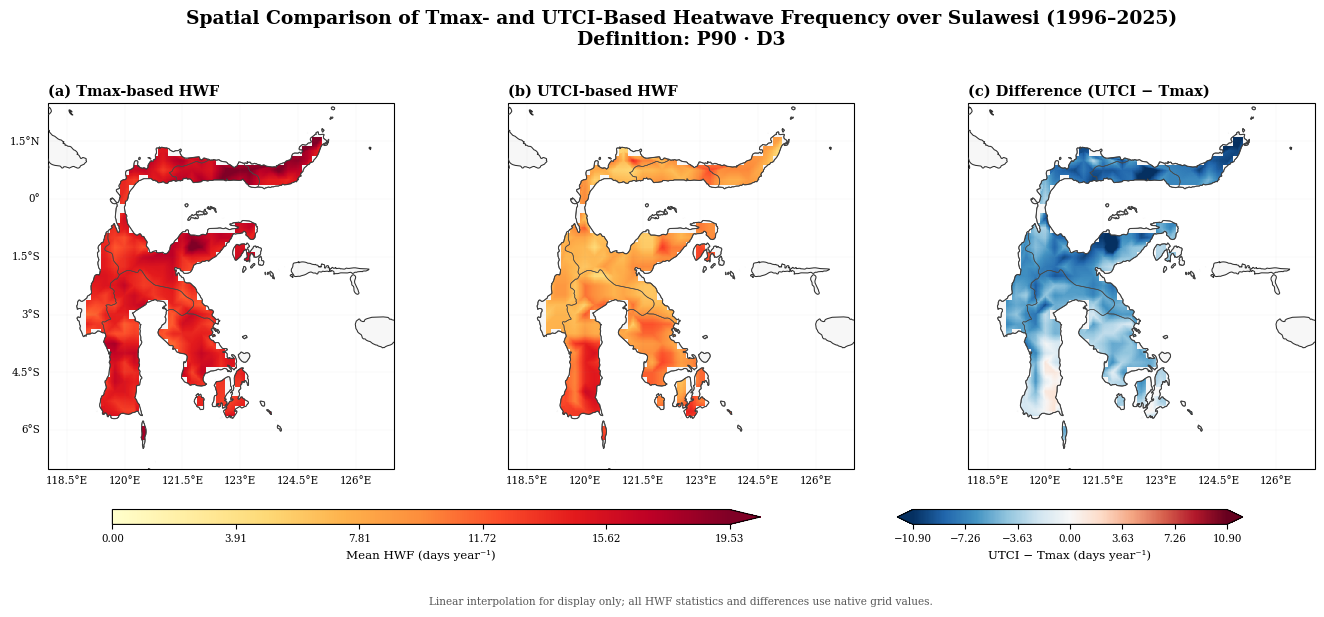

Saved: D:\MERLI\data\TMAX_UTCI_COMPARISON\plots_v2_pretty\FIG03_Spatial_HWF_V3_TMAX_vs_UTCI_P90_D3.png


In [8]:
# ============================================================
# FIGURE 3 — SPATIAL HWF COMPARISON, JOURNAL MAP V3
# ============================================================

# -----------------------------
# 1. LOAD TMAX METRIC CACHE
# -----------------------------
metric_cache = TMAX_CACHE / f"metrics_{MAIN_SCENARIO}_W15_{START_YEAR}_{END_YEAR}.npz"
if not metric_cache.exists():
    raise FileNotFoundError(f"Tmax metric cache tidak ditemukan: {metric_cache}")

ztm = np.load(metric_cache)
tmax_hwf_full = np.asarray(ztm["HWF"], dtype=float)

# Cache Tmax sudah mengikuti tmax_lat/tmax_lon ascending yang diperbaiki di Cell 3A.
tmax_hwf_cmp = np.take(
    np.take(tmax_hwf_full, tmax_lat_idx, axis=1),
    tmax_lon_idx,
    axis=2,
)
Tmap_raw = np.nanmean(tmax_hwf_cmp, axis=0)

# -----------------------------
# 2. LOAD UTCI METRIC
# -----------------------------
ud = xr.open_dataset(
    UTCI_METRICS_FILE,
    engine="netcdf4",
    decode_timedelta=False,
)
utci_hwf = ud["HWF"].sel(percentile=P, min_duration=D)
Umap_raw = np.nanmean(np.asarray(utci_hwf.values, dtype=float), axis=0)

if Tmap_raw.shape != Umap_raw.shape:
    raise RuntimeError(
        f"Spatial metric shape berbeda setelah alignment: Tmax={Tmap_raw.shape}, UTCI={Umap_raw.shape}"
    )

# Mask masing-masing basis untuk panel utamanya
Tmap = np.where(tmax_valid_grid, Tmap_raw, np.nan)
Umap = np.where(utci_valid_grid, Umap_raw, np.nan)

# Difference hanya di common support
Dmap = np.where(
    common_grid & np.isfinite(Tmap_raw) & np.isfinite(Umap_raw),
    Umap_raw - Tmap_raw,
    np.nan,
)

print("Spatial QC")
print("-----------")
print("Tmax finite cells      :", int(np.isfinite(Tmap).sum()))
print("UTCI finite cells      :", int(np.isfinite(Umap).sum()))
print("Common difference cells:", int(np.isfinite(Dmap).sum()))

# Jika alignment benar dan kedua dataset memakai mask Sulawesi yang sama,
# angka Tmax/UTCI seharusnya dekat atau identik.
ratio = np.isfinite(Tmap).sum() / max(1, np.isfinite(Umap).sum())
if ratio < 0.75 or ratio > 1.25:
    print(
        "PERINGATAN: coverage Tmax dan UTCI masih jauh berbeda. "
        "Cek output alignment/mask sebelum menginterpretasikan difference map."
    )

# -----------------------------
# 3. COLOR LEVELS
# -----------------------------
vals = np.concatenate([
    Tmap[np.isfinite(Tmap)],
    Umap[np.isfinite(Umap)],
])

vmax = float(np.nanpercentile(vals, 99)) if vals.size else 1.0
if not np.isfinite(vmax) or vmax <= 0:
    vmax = 1.0

# Level diskret = lebih mirip paper dan tidak terlalu pixelated.
main_levels = np.linspace(0.0, vmax, 11)

finite_diff = Dmap[np.isfinite(Dmap)]
dmax = float(np.nanpercentile(np.abs(finite_diff), 98)) if finite_diff.size else 1.0
if not np.isfinite(dmax) or dmax <= 0:
    dmax = 1.0

diff_levels = np.linspace(-dmax, dmax, 13)

# -----------------------------
# 4. PROVINCE GEOMETRIES
# -----------------------------
admin1 = shpreader.natural_earth(
    resolution="10m",
    category="cultural",
    name="admin_1_states_provinces",
)
SUL_GEOMS = []
for rec in shpreader.Reader(admin1).records():
    txt = " ".join(str(v).lower() for v in rec.attributes.values() if v is not None)
    if "indonesia" in txt and (("sulawesi" in txt) or ("gorontalo" in txt)):
        SUL_GEOMS.append(rec.geometry)


def setup_map_v3(ax, left_labels=False, bottom_labels=True):
    ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())

    # Background bersih seperti jurnal
    ax.set_facecolor("white")
    ax.add_feature(
        cfeature.LAND.with_scale("10m"),
        facecolor="#f7f7f7",
        edgecolor="none",
        zorder=0,
    )
    ax.add_feature(
        cfeature.OCEAN.with_scale("10m"),
        facecolor="white",
        edgecolor="none",
        zorder=0,
    )

    ax.coastlines(
        resolution="10m",
        linewidth=0.75,
        color="0.18",
        zorder=5,
    )

    for geom in SUL_GEOMS:
        ax.add_geometries(
            [geom],
            crs=ccrs.PlateCarree(),
            facecolor="none",
            edgecolor="0.28",
            linewidth=0.45,
            zorder=6,
        )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.25,
        linestyle=":",
        color="0.55",
        alpha=0.30,
        x_inline=False,
        y_inline=False,
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = left_labels
    gl.bottom_labels = bottom_labels
    gl.xlabel_style = {"size": 7.4}
    gl.ylabel_style = {"size": 7.4}


# -----------------------------
# 5. SMOOTH DISPLAY — EXACT SULAWESI GEOMETRY + NATIVE GRID SUPPORT
# -----------------------------
from scipy.interpolate import griddata, RegularGridInterpolator
from shapely.ops import unary_union
try:
    from shapely import contains_xy as _sulawesi_contains_xy
except ImportError:
    from shapely.vectorized import contains as _sulawesi_contains_xy

_cmp_geom = unary_union(SUL_GEOMS)
_cmp_lon2d, _cmp_lat2d = np.meshgrid(cmp_lon, cmp_lat)
_xfine = np.linspace(MAP_EXTENT[0], MAP_EXTENT[1], DISPLAY_NX)
_yfine = np.linspace(MAP_EXTENT[2], MAP_EXTENT[3], DISPLAY_NY)
_xx, _yy = np.meshgrid(_xfine, _yfine)
_land_mask = np.asarray(_sulawesi_contains_xy(_cmp_geom, _xx, _yy), dtype=bool)
_display_points = np.column_stack((_yy.ravel(), _xx.ravel()))


def comparison_display(z):
    """Render-only linear interpolation. Does not change actual HWF or differences."""
    values = np.asarray(z, dtype=float)
    good = np.isfinite(values)
    if good.sum() < 4:
        raise RuntimeError("Data native terlalu sedikit untuk interpolasi plot.")
    native_points = np.column_stack((_cmp_lon2d[good], _cmp_lat2d[good]))
    zfine = griddata(native_points, values[good], (_xx, _yy), method="linear")
    missing = _land_mask & ~np.isfinite(zfine)
    if np.any(missing):
        near = griddata(native_points, values[good], (_xx, _yy), method="nearest")
        zfine[missing] = near[missing]
    grid_support = RegularGridInterpolator(
        (cmp_lat, cmp_lon), good.astype(np.uint8),
        method="nearest", bounds_error=False, fill_value=0,
    )(_display_points).reshape(_xx.shape).astype(bool)
    zfine[~(_land_mask & grid_support)] = np.nan
    return zfine


def draw_hwf_comparison(ax, z, cmap, vmin, vmax):
    colors = mpl.colormaps[cmap].copy()
    colors.set_bad("white", alpha=0.0)
    if SPATIAL_RENDER == "smooth":
        return ax.pcolormesh(
            _xfine, _yfine, np.ma.masked_invalid(comparison_display(z)),
            shading="auto", cmap=colors, vmin=vmin, vmax=vmax,
            transform=ccrs.PlateCarree(), rasterized=True, zorder=2,
        )
    if SPATIAL_RENDER == "native":
        return ax.pcolormesh(
            cmp_lon, cmp_lat, np.ma.masked_invalid(z),
            shading="nearest", cmap=colors, vmin=vmin, vmax=vmax,
            transform=ccrs.PlateCarree(), rasterized=True, zorder=2,
        )
    raise ValueError("SPATIAL_RENDER harus smooth atau native")


fig = plt.figure(figsize=(14.4, 6.2))
gs = fig.add_gridspec(
    1, 3, left=0.035, right=0.965,
    bottom=0.245, top=0.835, wspace=0.10,
)
axes = [fig.add_subplot(gs[0, i], projection=ccrs.PlateCarree()) for i in range(3)]

m0 = draw_hwf_comparison(axes[0], Tmap, "YlOrRd", 0.0, vmax)
m1 = draw_hwf_comparison(axes[1], Umap, "YlOrRd", 0.0, vmax)
m2 = draw_hwf_comparison(axes[2], Dmap, "RdBu_r", -dmax, dmax)

panel_titles = [
    "(a) Tmax-based HWF", "(b) UTCI-based HWF", "(c) Difference (UTCI − Tmax)",
]
for i, (ax, title) in enumerate(zip(axes, panel_titles)):
    setup_map_v3(ax, left_labels=(i == 0), bottom_labels=True)
    ax.set_title(title, fontweight="bold", loc="left", pad=5)

# Di bawah panel, bukan menimpa data peta.
cax1 = fig.add_axes([0.105, 0.155, 0.450, 0.024])
cb1 = fig.colorbar(m1, cax=cax1, orientation="horizontal", ticks=main_levels[::2], extend="max")
cb1.set_label("Mean HWF (days year⁻¹)", fontsize=8.5)
cb1.ax.tick_params(labelsize=7.4)

cax2 = fig.add_axes([0.650, 0.155, 0.240, 0.024])
cb2 = fig.colorbar(m2, cax=cax2, orientation="horizontal", ticks=diff_levels[::2], extend="both")
cb2.set_label("UTCI − Tmax (days year⁻¹)", fontsize=8.5)
cb2.ax.tick_params(labelsize=7.4)

fig.suptitle(
    f"Spatial Comparison of Tmax- and UTCI-Based Heatwave Frequency over Sulawesi ({START_YEAR}–{END_YEAR})\n"
    f"Definition: {MAIN_SCENARIO.replace('_', ' · ')}",
    fontweight="bold", y=0.985,
)
fig.text(0.5, 0.025,
         "Linear interpolation for display only; all HWF statistics and differences use native grid values.",
         ha="center", fontsize=7.6, color="0.35")

sp_png = PLOT_DIR / f"FIG03_Spatial_HWF_V3_TMAX_vs_UTCI_{MAIN_SCENARIO}.png"
fig.savefig(sp_png, dpi=FIG_DPI, bbox_inches="tight", facecolor="white")
if SAVE_PDF:
    fig.savefig(sp_png.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)
print("Saved:", sp_png)


## 8. Ringkasan interpretasi yang aman

Saat membaca figure perbandingan:

- Kalau **Tmax-based > UTCI-based** untuk HWN/HWF/HWD, artinya definisi berbasis Tmax mendeteksi lebih banyak/lebih panjang event pada konfigurasi threshold yang sama.
- Kalau **UTCI-based > Tmax-based**, artinya kombinasi suhu, kelembapan, angin, dan radiasi yang direpresentasikan UTCI membuat kondisi thermal stress lebih sering melewati threshold relatifnya.
- Untuk HWA/HWM, jangan menyebut selisih UTCI–Tmax sebagai “selisih suhu udara”. UTCI adalah **equivalent temperature/thermal index**.
- Panel agreement pada case study membantu melihat apakah kedua definisi mendeteksi **grid yang sama**, bukan cuma menghasilkan jumlah grid yang kebetulan mirip.


In [9]:
# ============================================================
# 8. FINAL OUTPUT CHECK
# ============================================================

print("\n========== OUTPUT PLOT ==========")
for p in sorted(PLOT_DIR.glob("*.png")):
    print(" -", p.name)

print("\n========== OUTPUT TABLE ==========")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print(" -", p.name)

print("\nSelesai. Kalau case otomatis kurang menarik, set AUTO_CASE=False dan isi CASE_CENTER.")



========== OUTPUT PLOT ==========
 - FIG01_Annual_TMAX_vs_UTCI_P90_D3_absolute.png
 - FIG02_CaseStudy_PRETTY_TMAX_vs_UTCI_P90_D3_20130621.png
 - FIG02_CaseStudy_PRETTY_TMAX_vs_UTCI_P90_D3_20240101.png
 - FIG03_Spatial_HWF_PRETTY_TMAX_vs_UTCI_P90_D3.png
 - FIG03_Spatial_HWF_V3_TMAX_vs_UTCI_P90_D3.png

========== OUTPUT TABLE ==========
 - Annual_Comparison_Trend_Summary.csv
 - CaseStudy_Daily_Comparison_PRETTY.csv

Selesai. Kalau case otomatis kurang menarik, set AUTO_CASE=False dan isi CASE_CENTER.
